<a href="https://colab.research.google.com/github/ntienvo/ML-lab/blob/main/Lab07_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab07 – Logistic Regression
**Course:** Machine Learning | **Dataset:** Breast Cancer Wisconsin (Diagnostic)

## Learning objectives
- Explain the sigmoid function and probability output.
- Implement logistic regression, binary cross-entropy, and gradient descent using NumPy.
- Visualize a two-feature decision boundary.
- Evaluate a binary classifier and compare it with Scikit-learn.

**Implementation policy:** Core algorithm components (sigmoid, prediction, BCE, gradient descent, and metrics) are implemented from scratch with NumPy. Dataset loading, splitting, scaling, plotting, and the reference model use libraries.

**Target convention in Scikit-learn:** `0 = malignant`, `1 = benign`.

## A. Dataset Information and Preparation (Provided)

The dataset contains 569 samples, 30 numeric features, and two classes. The following cells load the data, split it into training and test sets, and standardize features. Exploration is intentionally provided.

`StandardScaler` is fitted only on the training set to avoid data leakage.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

In [ ]:
dataset = load_breast_cancer()
X, y = dataset.data, dataset.target
feature_names = dataset.feature_names

print("Dataset shape:", X.shape)
print("Features:", len(feature_names))
print("Target mapping: 0 = malignant, 1 = benign")
print("Class counts:", dict(zip(*np.unique(y, return_counts=True))))

Dataset shape: (569, 30)
Features: 30
Target mapping: 0 = malignant, 1 = benign
Class counts: {np.int64(0): np.int64(212), np.int64(1): np.int64(357)}


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Training:", X_train_scaled.shape, "Testing:", X_test_scaled.shape)

Training: (455, 30) Testing: (114, 30)


### Dataset snapshot

| Property | Value |
|---|---:|
| Samples | 569 |
| Features | 30 |
| Classes | 2 |
| Class 0 | Malignant |
| Class 1 | Benign |

The main model uses all 30 features. A separate two-feature model is used only to visualize a decision boundary.

## B. Sigmoid Function

Logistic regression computes a linear score and maps it to a probability:

$$z=\mathbf{w}^T\mathbf{x}+b, \qquad \sigma(z)=\frac{1}{1+e^{-z}}$$

### B1. Implement sigmoid

Complete the function using NumPy. It should accept a scalar or an array.

In [ ]:
def sigmoid(z):
    # TODO: implement sigmoid function.
    return 1.0 / (1.0 + np.exp(-z))
    pass

### B2. Test sigmoid

In [ ]:
test_values = np.array([-5, -2, 0, 2, 5], dtype=float)
# TODO: Call sigmoid() and print the output.

[0.00669285 0.11920292 0.5        0.88079708 0.99330715]


### B3. Plot sigmoid

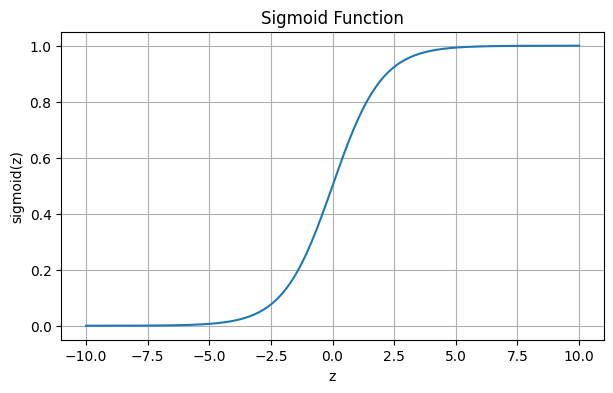

In [ ]:
z_values = np.linspace(-10, 10, 200)
# TODO: Compute sigmoid(z_values), then plot the curve.
# Include axis labels, a title, and a grid.

**Questions**
1. What is the range of sigmoid?
2. What is its output when $z=0$?
3. What happens when $z$ is a very large positive or negative number?

## C. Logistic Regression Prediction

For each sample:

$$z=\sum_{j=1}^{d}w_jx_j+b, \qquad \hat y=\sigma(z)$$

The probability is converted to a class using threshold 0.5: predict class 1 when $\hat y\geq0.5$, otherwise class 0.

### C1. Implement probability prediction

In [ ]:
def predict_proba(X, w, b):
    # TODO: Compute z = X @ w + b and return sigmoid(z).
    pass

### C2. Implement class prediction

In [ ]:
def predict(X, w, b, threshold=0.5):
    # TODO: Convert predicted probabilities to 0/1 labels.
    pass

### C3. Initialize parameters

In [ ]:
n_features = X_train_scaled.shape[1]
# TODO: Initialize w as a zero vector and b as 0.0.

## D. Binary Cross-Entropy Loss

$$J(\mathbf{w},b)=-\frac{1}{m}\sum_{i=1}^{m}\left[y^{(i)}\log(\hat y^{(i)})+(1-y^{(i)})\log(1-\hat y^{(i)})\right]$$

Clip probabilities slightly away from 0 and 1 to avoid `log(0)`.

### D1. Implement BCE

In [ ]:
def compute_loss(y_true, y_prob):
    epsilon = 1e-7
    # TODO: Clip probabilities to [epsilon, 1-epsilon].
    # TODO: Compute and return mean binary cross-entropy.
    pass

### D2. Test BCE

In [ ]:
y_true_example = np.array([0, 1, 1, 0])
y_prob_example = np.array([0.1, 0.8, 0.6, 0.3])
# TODO: Compute and print the loss.

**Question:** Why is binary cross-entropy more informative than simply counting incorrect predictions?

## E. Gradient Descent

For logistic regression with sigmoid and BCE:

$$\frac{\partial J}{\partial w_j}=\frac{1}{m}\sum_{i=1}^{m}(\hat y^{(i)}-y^{(i)})x_j^{(i)}$$

$$\frac{\partial J}{\partial b}=\frac{1}{m}\sum_{i=1}^{m}(\hat y^{(i)}-y^{(i)})$$

Update parameters using $w_j\leftarrow w_j-\alpha\frac{\partial J}{\partial w_j}$ and $b\leftarrow b-\alpha\frac{\partial J}{\partial b}$.

### E1. Implement training with vectorized NumPy

In [ ]:
def train_logistic_regression(X, y, learning_rate=0.1, n_iterations=2000):
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    b = 0.0
    loss_history = []

    for iteration in range(n_iterations):
        # TODO: Compute probabilities and errors (y_prob - y).
        # TODO: Compute dw = X.T @ errors / n_samples.
        # TODO: Compute db = sum(errors) / n_samples.
        # TODO: Update w and b; compute and store the loss.
        pass

    return w, b, loss_history

### E2. Train the full-feature model

In [ ]:
learning_rate = 0.1
n_iterations = 2000
# TODO: Train using X_train_scaled and y_train.
# Save outputs as w_trained, b_trained, loss_history.

### E3. Plot training loss

In [ ]:
# TODO: Plot loss_history against iteration with labels and a grid.
plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("Iteration");
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training Loss");
plt.grid(True);
plt.show()

**Questions**
1. What does decreasing loss indicate?
2. What may happen if the learning rate is too large?
3. What may happen if it is too small?

## F. Decision Boundary Visualization

The full model uses 30 features, so its decision boundary cannot be drawn directly in 2D. For visualization only, use `mean radius` and `mean texture` to train a separate two-feature model.

In [ ]:
feature_indices = [
    list(feature_names).index("mean radius"),
    list(feature_names).index("mean texture")
]
X_2d = X[:, feature_indices]
X_2d_train, X_2d_test, y_2d_train, y_2d_test = train_test_split(
    X_2d, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
scaler_2d = StandardScaler()
X_2d_train_scaled = scaler_2d.fit_transform(X_2d_train)
X_2d_test_scaled = scaler_2d.transform(X_2d_test)
print("Selected features:", feature_names[feature_indices])

### F1. Train the two-feature model

In [ ]:
# TODO: Train your NumPy logistic regression model on X_2d_train_scaled.
# Store the parameters as w_2d and b_2d.

### F2. Plot the decision boundary

In [ ]:
x_min, x_max = X_2d_train_scaled[:, 0].min()-1, X_2d_train_scaled[:, 0].max()+1
y_min, y_max = X_2d_train_scaled[:, 1].min()-1, X_2d_train_scaled[:, 1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250),
                     np.linspace(y_min, y_max, 250))
grid = np.c_[xx.ravel(), yy.ravel()]

# TODO: Predict probabilities for grid and reshape to xx.shape.
# TODO: Use contourf() for regions and scatter() for training samples.
# Add labels, title, legend, and grid.
grid_prob = predict_proba(grid, w_2d, b_2d).reshape(xx.shape)
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, grid_prob, levels=[0, 0.5, 1], alpha=0.25)
points = plt.scatter(X_2d_train_scaled[:, 0], X_2d_train_scaled[:, 1],
                     c=y_2d_train, edgecolors="k", alpha=0.75)
plt.xlabel("Standardized mean radius");
plt.ylabel("Standardized mean texture")
plt.title("Decision Boundary (Two Features)")
plt.legend(*points.legend_elements(), title="Class")
plt.grid(True);
plt.show()

## G. Model Evaluation

Treat class 1 (benign) as the positive class in this lab.

- TP: actual 1, predicted 1
- TN: actual 0, predicted 0
- FP: actual 0, predicted 1
- FN: actual 1, predicted 0

$$Accuracy=\frac{TP+TN}{TP+TN+FP+FN}$$
$$Precision=\frac{TP}{TP+FP},\quad Recall=\frac{TP}{TP+FN}$$
$$F1=2\frac{Precision\cdot Recall}{Precision+Recall}$$

### G1. Predict test labels

In [ ]:
# TODO: Predict labels for X_test_scaled using w_trained and b_trained.
# Store the result in y_pred_numpy.

### G2. Implement metrics from scratch

In [ ]:
def accuracy_score_numpy(y_true, y_pred):
    # TODO
    pass

def precision_score_numpy(y_true, y_pred):
    # TODO: class 1 is positive; return 0 if no predicted positives.
    pass

def recall_score_numpy(y_true, y_pred):
    # TODO: class 1 is positive; return 0 if no actual positives.
    pass

def f1_score_numpy(y_true, y_pred):
    # TODO: Use precision and recall; handle zero denominator.
    pass

### G3. Calculate the metrics

In [ ]:
# TODO: Calculate and print Accuracy, Precision, Recall, and F1-score.
# Store results in a dictionary named numpy_metrics.

### G4. Verify with Scikit-learn

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
# TODO: Calculate the same metrics and print confusion matrix
# and classification report.

**Questions**
1. Why evaluate on the test set rather than the training set?
2. In medical screening, what does a false negative mean?
3. Why can recall be important when identifying malignant cases?
4. Which class is positive in this lab?

## H. Scikit-learn Workflow and Comparison

### H1. Train Scikit-learn Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

sk_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
sk_model.fit(X_train_scaled, y_train)
y_pred_sk = sk_model.predict(X_test_scaled)

### H2. Compare results

In [ ]:
# TODO: Calculate Scikit-learn metrics.
# TODO: Compare them with numpy_metrics in a compact table.
sk_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_sk),
    "Precision": precision_score(y_test, y_pred_sk, zero_division=0),
    "Recall": recall_score(y_test, y_pred_sk, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_sk, zero_division=0)
}
print(f"{'Metric':<12} {'NumPy':>10} {'Scikit-learn':>15}")
for name in numpy_metrics:
    print(f"{name:<12} {numpy_metrics[name]:>10.4f} {sk_metrics[name]:>15.4f}")

### H3. Reflection

1. What are the main steps of logistic regression prediction?
2. What is the role of sigmoid?
3. Why use binary cross-entropy?
4. How does gradient descent learn weights and bias?
5. Why might NumPy and Scikit-learn results differ?
6. Which implementation would you choose in a real application, and why?